In [1]:
# Importation des bibliothèques nécessaires à l'analyse
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from adjustText import adjust_text

warnings.filterwarnings("ignore")  
sns.set(style="whitegrid") 

In [2]:
# Cette fonction parcourt tous les fichiers de stations d’un département, extrait la colonne de température et 
# calcule pour chaque station plusieurs indicateurs statistiques utilisés ensuite pour le clustering.

def load_department(dept):
    folder = f"DEPT_{dept}" 
    pattern = os.path.join(folder, f"DEPT_{dept}_STATION_*.csv")
    files = sorted(glob.glob(pattern))
    rows = []

    # Lecture des fichiers de stations
    for fpath in files:  
        df = pd.read_csv(fpath, sep=";", encoding="utf-8")
        if "T" not in df.columns:    # Ignore si pas de température
            continue
        
        t = pd.to_numeric(df["T"], errors="coerce").dropna()
        if t.empty:                  # Ignore si aucune valeur exploitable
            continue
        
        sid = os.path.basename(fpath).split("_STATION_")[1].split(".")[0] 

        # Ajout des statistiques descriptives de la station
        rows.append({
            "station_id": sid,
            "mean_T": t.mean(),
            "median_T": t.median(),
            "std_T": t.std(),
            "min_T": t.min(),
            "max_T": t.max(),
            "range_T": t.max() - t.min(),
            "skew_T": t.skew(),
            "kurt_T": t.kurt(),
            "q1_T": t.quantile(0.25),
            "q3_T": t.quantile(0.75)
        })

    features = pd.DataFrame(rows)
    if features.empty: 
        return features
    
    features = features.set_index("station_id")    # Station ID comme index
    return features

In [3]:
# Ces fonctions déterminent le nombre optimal de clusters : elbow_k estime le point du coude, 
# et choose_k combine elbow et silhouette pour sélectionner la valeur de K la plus cohérente.

def elbow_k(K_values, inertias):
    inertias = np.array(inertias, dtype=float)
    if len(inertias) < 3:                     # Trop peu de points pour un coude fiable
        return K_values[len(K_values)//2]
    second_diff = np.diff(inertias, 2)        # Approximation de la courbure
    idx = np.argmin(second_diff)
    return K_values[idx + 1]

def choose_k(K_values, inertias, silhouettes):
    silhouettes = np.array(silhouettes, dtype=float)

    k_elbow = elbow_k(K_values, inertias)     # Valeur suggérée par le coude
    valid = ~np.isnan(silhouettes)            # Silhouettes calculables

    if not np.any(valid):                     # Si aucune silhouette valide
        return k_elbow, k_elbow, k_elbow

    K_valid = np.array(K_values)[valid]
    sil_valid = silhouettes[valid]
    k_sil = K_valid[np.argmax(sil_valid)]     # K optimisé par silhouette

    # Choix final : cohérence entre elbow et silhouette
    if abs(k_sil - k_elbow) <= 1:
        best_k = k_sil
    else:
        best_k = k_elbow

    return best_k, k_sil, k_elbow

In [4]:
# Cette fonction trace la projection PCA des stations et colore les points selon leurs clusters.
# Elle ajoute également les étiquettes des stations et enregistre le graphique.

def plot_pca(df, col1, col2, cluster_col, title, out_path, pca_model):
    expl = pca_model.explained_variance_ratio_ * 100
    plt.figure(figsize=(10, 8))

    clusters = sorted(df[cluster_col].unique())    # Liste des clusters
    colors = plt.cm.tab10(np.linspace(0, 1, len(clusters)))

    texts = []   

    # Tracé des points par cluster
    for c, color in zip(clusters, colors):        
        subset = df[df[cluster_col] == c]

        plt.scatter(subset[col1], subset[col2], s=90, color=color,
            edgecolor="black", linewidth=0.6, alpha=0.85, label=f"Cluster {c}")

        # Ajout des étiquettes
        for idx, row in subset.iterrows():       
            txt = plt.text(row[col1] + 0.03, row[col2] + 0.03, str(idx), fontsize=7, color="black")
            texts.append(txt)

    adjust_text(
        texts,
        force_text=0.5,
        force_points=0.5,
        expand_points=(1.1, 1.3),
        expand_text=(1.1, 1.3),
        arrowprops=None
    )

    plt.xlabel(f"PCA1 ({expl[0]:.2f}%)")
    plt.ylabel(f"PCA2 ({expl[1]:.2f}%)")
    plt.title(title, fontsize=14)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)  
    plt.show()

In [5]:
# Ce bloc charge les données de chaque département, crée le dossier de sortie,
# stocke les tables de caractéristiques et affiche un aperçu des 5 premières lignes.

departments = [61, 69]
data = {}

for dept in departments:
    df = load_department(dept)                   # Chargement des caractéristiques du département
    out_dir = f"DEPT_{dept}_OUTPUTS"
    os.makedirs(out_dir, exist_ok=True)          # Création du dossier de sortie

    data[dept] = {"df": df, "out_dir": out_dir}  # Sauvegarde dans le dictionnaire

    print(f"\nDEPARTMENT {dept}: FEATURE TABLE")
    display(df.head())  


DEPARTMENT 61: FEATURE TABLE


,mean_T,median_T,std_T,min_T,max_T,range_T,skew_T,kurt_T,q1_T,q3_T
station_id,,,,,,,,,,
61001001,11.207339,11.0,6.844860,-13.3,39.3,52.6,0.196481,-0.082400,6.5,15.8
61006005,11.011393,10.8,6.787868,-14.6,40.1,54.7,0.193577,0.020215,6.4,15.5
61074004,10.338110,10.1,6.523361,-14.0,36.1,50.1,0.231019,0.054341,5.9,14.6
61124001,15.792394,15.3,4.245851,6.9,30.2,23.3,0.651401,0.334300,12.7,18.3
61133001,10.525086,10.4,6.677560,-12.8,37.4,50.2,0.177429,-0.125773,5.9,15.0



DEPARTMENT 69: FEATURE TABLE


,mean_T,median_T,std_T,min_T,max_T,range_T,skew_T,kurt_T,q1_T,q3_T
station_id,,,,,,,,,,
69008001,11.903949,11.5,7.919194,-8.4,39.6,48.0,0.241675,-0.440607,6.0,17.4
69023002,12.327575,12.3,7.866232,-11.4,39.2,50.6,0.080190,-0.484450,6.5,18.0
69028001,12.364249,12.2,8.159257,-13.9,40.5,54.4,0.185128,-0.432754,6.2,18.1
69029001,13.027866,12.8,8.235195,-12.4,41.0,53.4,0.139622,-0.501576,6.8,18.9
69058002,11.669132,11.5,7.788712,-12.0,37.0,49.0,0.084304,-0.502328,5.9,17.3


In [6]:
# Ce bloc standardise les caractéristiques, teste plusieurs valeurs de K pour K-Means,
# calcule l'inertie et le score de silhouette, puis sélectionne le nombre optimal de clusters.

for dept in departments:
    df = data[dept]["df"]
    out_dir = data[dept]["out_dir"]

    feature_cols = [
        "mean_T", "median_T", "std_T", "min_T", "max_T",
        "range_T", "skew_T", "kurt_T", "q1_T", "q3_T"
    ]

    X = StandardScaler().fit_transform(df[feature_cols])  # Normalisation
    data[dept]["X"] = X

    max_k = min(10, X.shape[0] - 1)                       # Limite supérieure pour K
    K_values = list(range(2, max_k + 1))
    inertias = []
    silhouettes = []

    # Test des différentes valeurs de K
    for K in K_values:  
        km = KMeans(n_clusters=K, random_state=58, n_init=10)
        lbls = km.fit_predict(X)
        inertias.append(km.inertia_)                    # Inertie pour la méthode du coude

        if len(np.unique(lbls)) > 1:
            try:
                sil = silhouette_score(X, lbls)         # Score de silhouette
            except:
                sil = np.nan
        else:
            sil = np.nan

        silhouettes.append(sil)

    best_k, ks, ke = choose_k(K_values, inertias, silhouettes)    # Sélection de K

    data[dept]["best_k"] = best_k
    data[dept]["K_values"] = K_values
    data[dept]["inertias"] = inertias
    data[dept]["silhouettes"] = silhouettes

    print(f"\nDepartment {dept}:")
    print(f"Chosen K = {best_k}")
    print(f"Silhouette suggested = {ks}")
    print(f"Elbow suggested = {ke}")


Department 61:
Chosen K = 7
Silhouette suggested = 2
Elbow suggested = 7

Department 69:
Chosen K = 8
Silhouette suggested = 2
Elbow suggested = 8


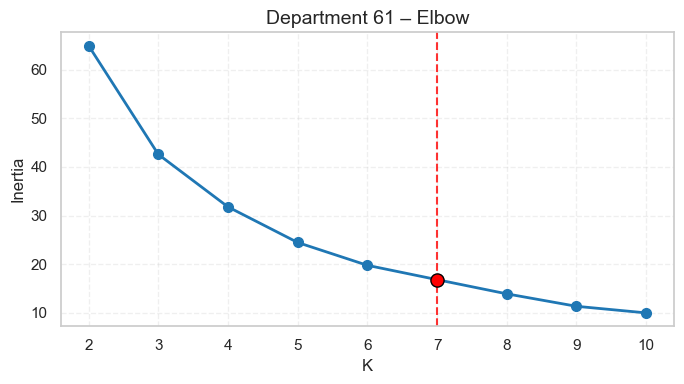

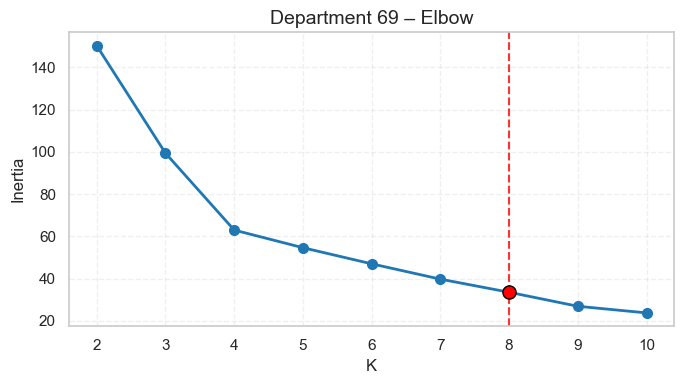

In [7]:
# Ce bloc trace la courbe de l'inertie pour la méthode du coude
# et met en évidence la valeur de K sélectionnée pour chaque département.

for dept in departments:
    out_dir = data[dept]["out_dir"]
    K_values = data[dept]["K_values"]
    inertias = data[dept]["inertias"]
    best_k = data[dept]["best_k"]

    plt.figure(figsize=(7, 4))

    # Courbe de l'inertie
    plt.plot(K_values, inertias, marker="o", markersize=7, linewidth=2, color="#1f77b4")

    # Ligne verticale pour le meilleur K
    plt.axvline(best_k, linestyle="--", color="red", alpha=0.8)

    # Point du coude mis en évidence
    best_k_index = K_values.index(best_k)
    plt.scatter([best_k], [inertias[best_k_index]], color="red", edgecolor="black", s=90, zorder=5)

    plt.title(f"Department {dept} – Elbow", fontsize=14)
    plt.xlabel("K", fontsize=12)
    plt.ylabel("Inertia", fontsize=12)

    plt.grid(True, linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "elbow.png"), dpi=300)
    plt.show()

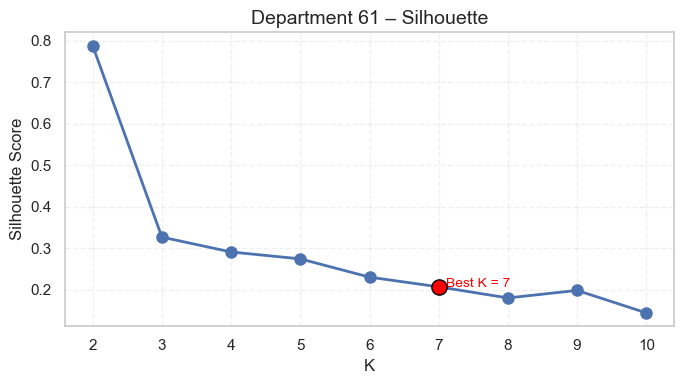

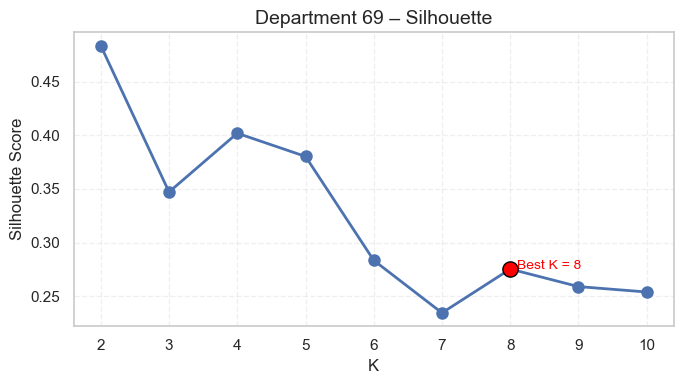

In [8]:
# Ce bloc trace la courbe des scores de silhouette pour chaque valeur de K et met en évidence le K retenu pour le clustering.

for dept in departments:
    out_dir = data[dept]["out_dir"]
    K_values = data[dept]["K_values"]
    silhouettes = data[dept]["silhouettes"]
    best_k = data[dept]["best_k"]

    plt.figure(figsize=(7,4))
    plt.plot(K_values, silhouettes, marker="o", markersize=8, linewidth=2)

    # Point correspondant au meilleur K
    plt.scatter([best_k], [silhouettes[K_values.index(best_k)]], color="red", s=120, edgecolor="black", zorder=5)

    plt.title(f"Department {dept} – Silhouette", fontsize=14)
    plt.xlabel("K", fontsize=12)
    plt.ylabel("Silhouette Score", fontsize=12)

    plt.grid(True, linestyle="--", alpha=0.3)

    # Annotation du meilleur score
    plt.text(best_k + 0.1, silhouettes[K_values.index(best_k)], f"Best K = {best_k}", fontsize=10, color="red")

    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "silhouette.png"), dpi=300)
    plt.show()

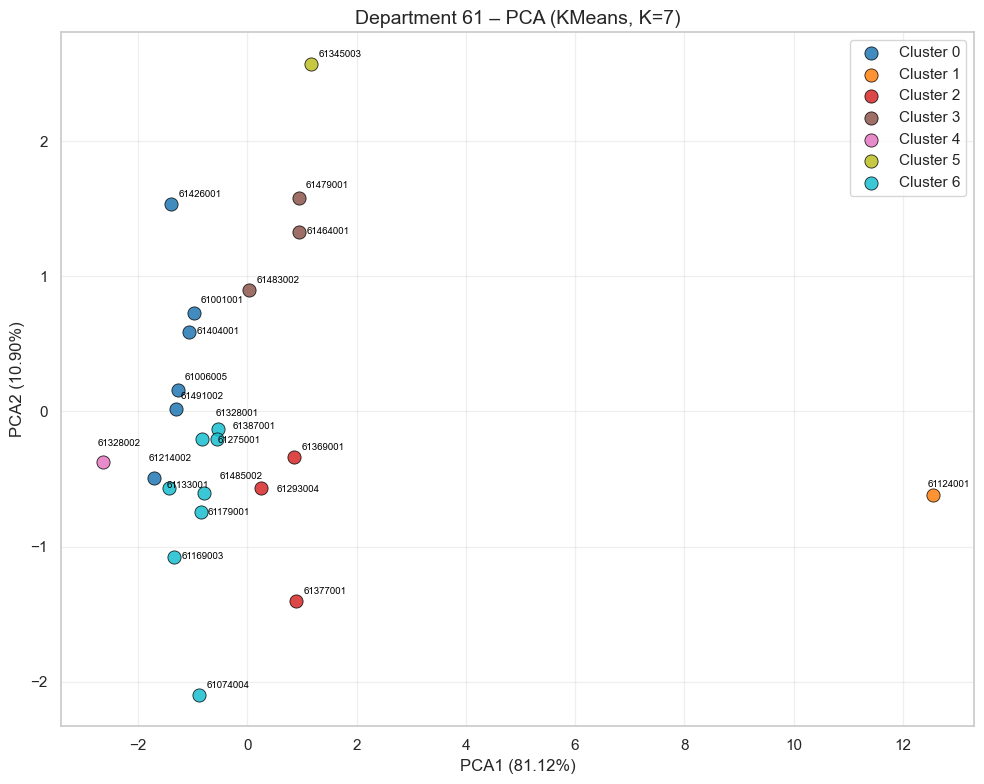

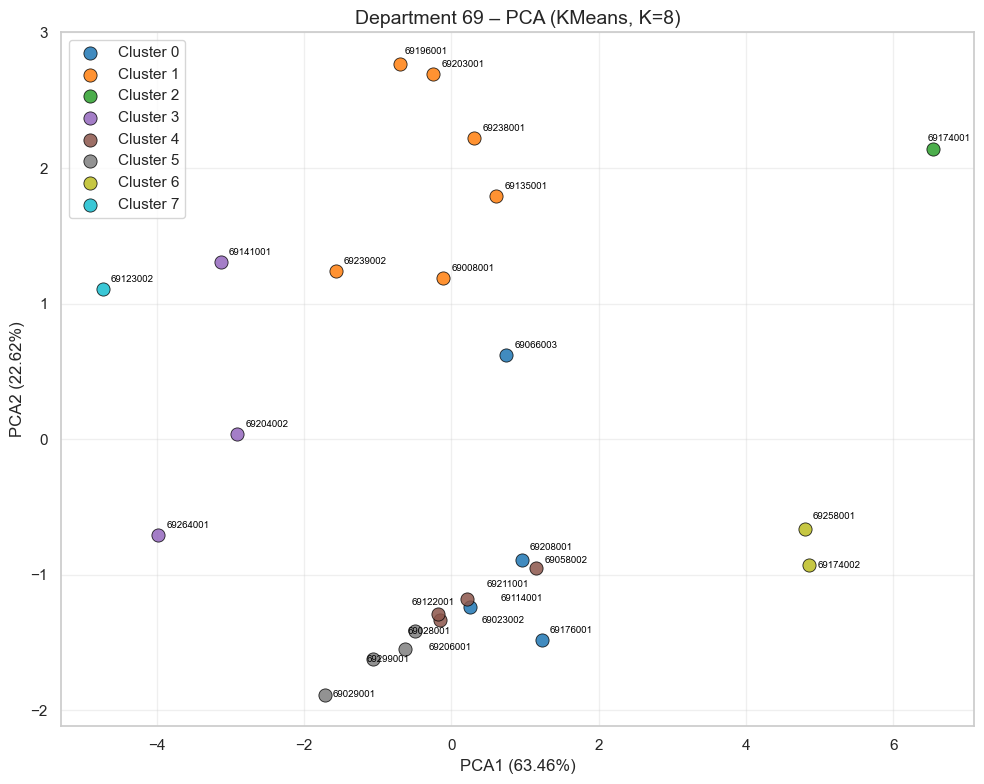

In [9]:
# Ce bloc applique K-Means avec le K sélectionné, réalise une PCA à deux composantes,
# ajoute les coordonnées PCA au tableau et génère le graphique PCA des clusters.

for dept in departments:
    df = data[dept]["df"]          
    X = data[dept]["X"]            
    out_dir = data[dept]["out_dir"]
    best_k = data[dept]["best_k"]

    # Clustering K-Means
    kmeans = KMeans(n_clusters=best_k, random_state=58, n_init=10)
    df["cluster_kmeans"] = kmeans.fit_predict(X)

    # PCA en 2 dimensions
    pca = PCA(n_components=2, random_state=58)
    coords = pca.fit_transform(X)

    df["PCA1"] = coords[:, 0]
    df["PCA2"] = coords[:, 1]

    data[dept]["pca"] = pca 

    # Graphique PCA pour les clusters K-Means
    plot_pca(df, "PCA1", "PCA2", "cluster_kmeans", f"Department {dept} – PCA (KMeans, K={best_k})",
        os.path.join(out_dir, "pca_kmeans.png"), pca)

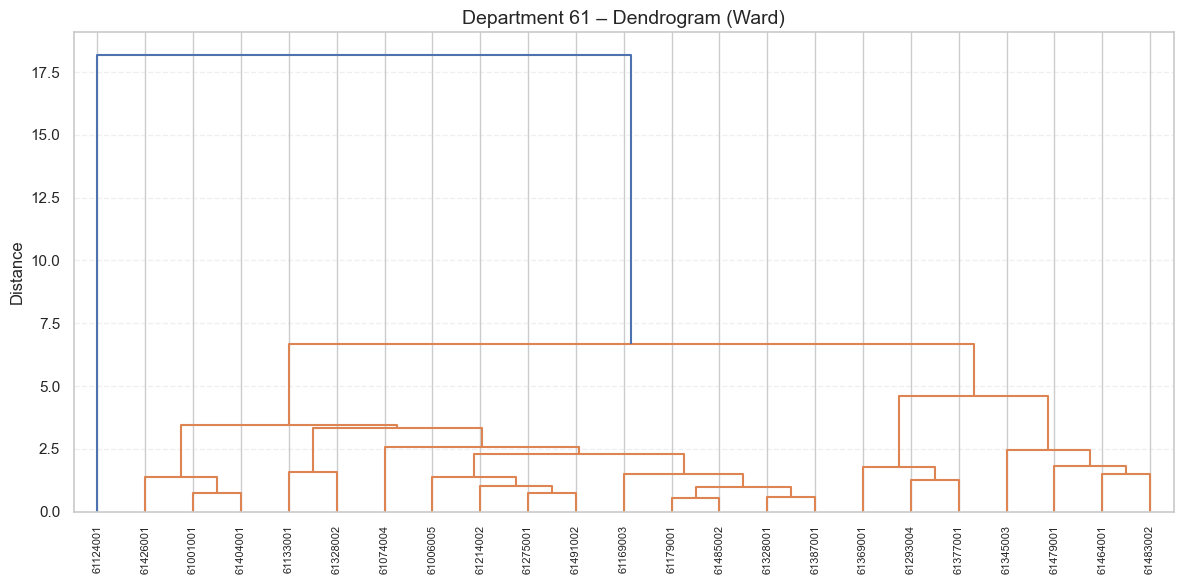

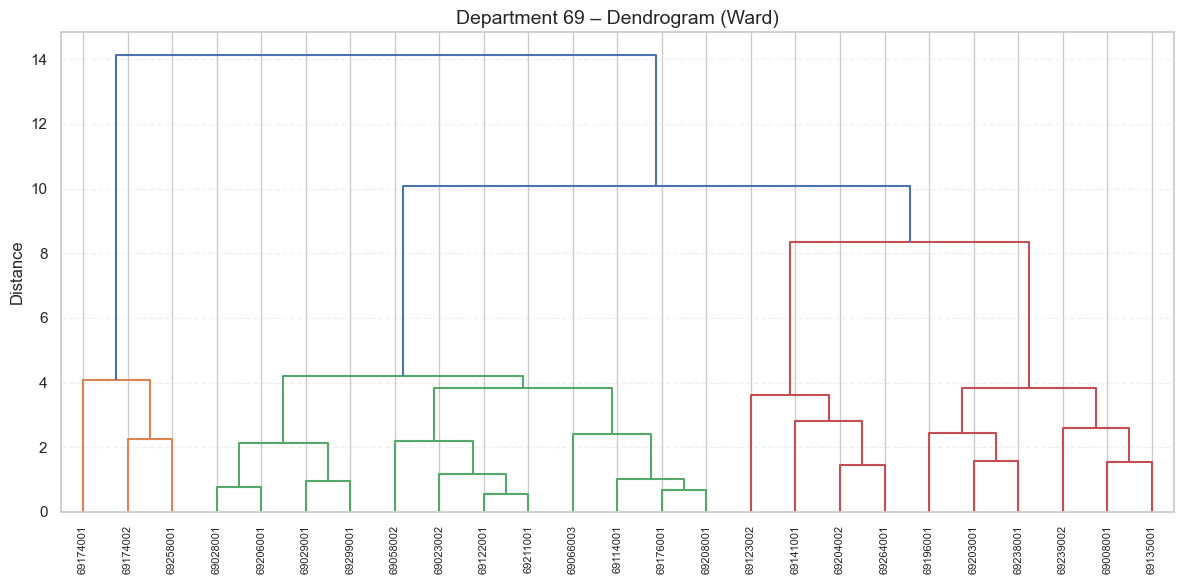

In [10]:
# Ce bloc effectue le clustering hiérarchique avec la méthode de Ward,
# génère le dendrogramme pour visualiser la structure des regroupements
# et sauvegarde la figure pour chaque département.

for dept in departments:
    df = data[dept]["df"]
    X = data[dept]["X"]
    out_dir = data[dept]["out_dir"]

    Z = linkage(X, method="ward")      # Matrice hiérarchique
    threshold = 0.7 * max(Z[:, 2])     # Seuil pour la coloration des branches

    plt.figure(figsize=(12, 6))
    dendrogram(
        Z,
        labels=df.index.tolist(),  
        leaf_rotation=90,
        leaf_font_size=8,
        color_threshold=threshold
    )

    plt.title(f"Department {dept} – Dendrogram (Ward)", fontsize=14)
    plt.ylabel("Distance")
    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "dendrogram.png"), dpi=300)
    plt.show()

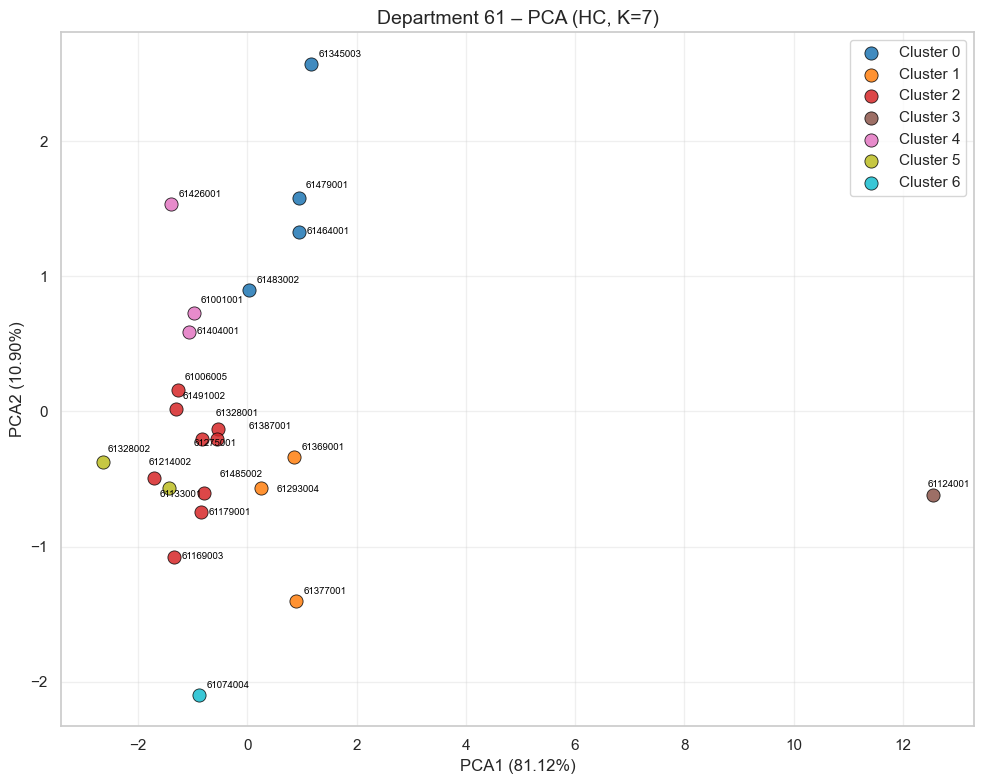

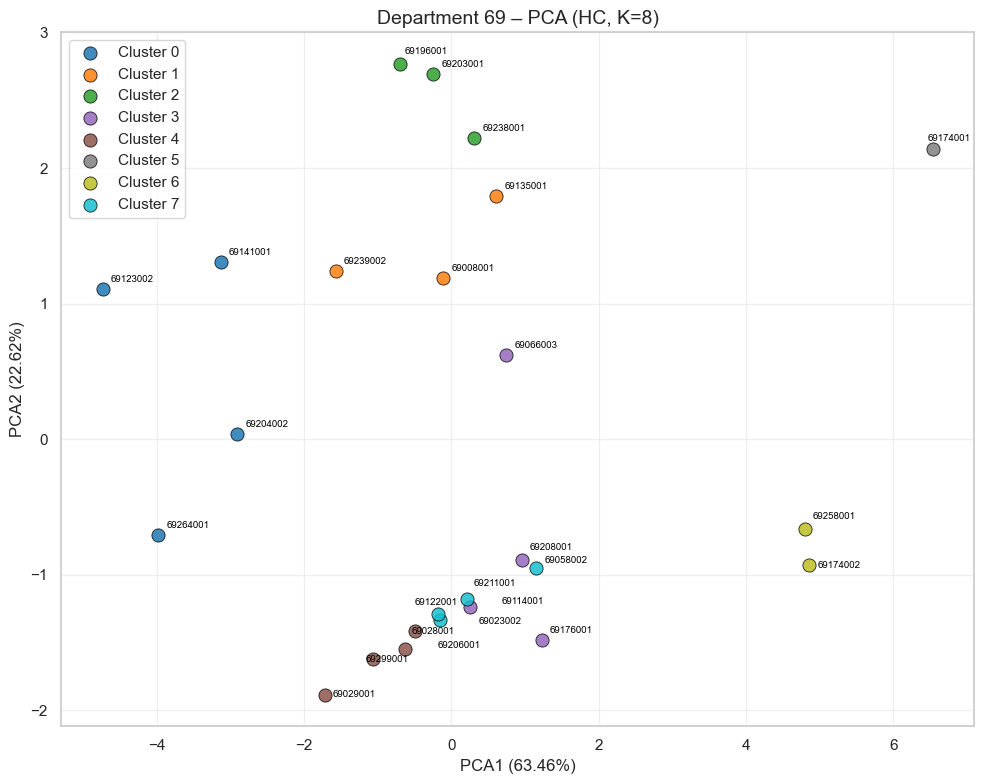

In [11]:
# Ce bloc applique le clustering hiérarchique (Ward) avec le K sélectionné,
# ajoute les labels obtenus au tableau et produit la visualisation PCA correspondante.

for dept in departments:
    df = data[dept]["df"]
    X = data[dept]["X"]
    out_dir = data[dept]["out_dir"]
    pca = data[dept]["pca"]
    best_k = data[dept]["best_k"]

    hc = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
    df["cluster_hc"] = hc.fit_predict(X)  

    # Graphique PCA des clusters hiérarchiques
    plot_pca(df, "PCA1", "PCA2", "cluster_hc", f"Department {dept} – PCA (HC, K={best_k})",
             os.path.join(out_dir, "pca_hc.png"), pca)

cluster_hc,0,1,2,3,4,5,6
cluster_kmeans,,,,,,,
0,0,0,3,0,3,0,0
1,0,0,0,1,0,0,0
2,0,3,0,0,0,0,0
3,3,0,0,0,0,0,0
4,0,0,0,0,0,1,0
5,1,0,0,0,0,0,0
6,0,0,6,0,0,1,1


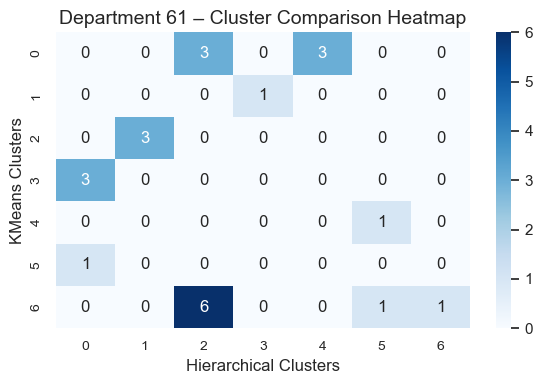

cluster_hc,0,1,2,3,4,5,6,7
cluster_kmeans,,,,,,,,
0,0,0,0,4,0,0,0,0
1,0,3,3,0,0,0,0,0
2,0,0,0,0,0,1,0,0
3,3,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,4
5,0,0,0,0,4,0,0,0
6,0,0,0,0,0,0,2,0
7,1,0,0,0,0,0,0,0


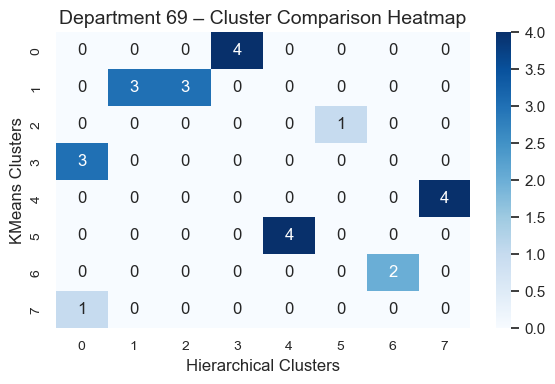

In [12]:
# Ce bloc compare les clusters obtenus par K-Means et par clustering hiérarchique,
# affiche une table croisée et une heatmap, puis exporte les résultats complets.

for dept in departments:
    df = data[dept]["df"]
    out_dir = data[dept]["out_dir"]

    # Tableau croisé entre les deux méthodes
    ctab = pd.crosstab(df["cluster_kmeans"], df["cluster_hc"])
    display(ctab)

    plt.figure(figsize=(6,4))
    sns.heatmap(ctab, annot=True, cmap="Blues", fmt="d", cbar=True)

    plt.title(f"Department {dept} – Cluster Comparison Heatmap", fontsize=14)
    plt.xlabel("Hierarchical Clusters", fontsize=12)
    plt.ylabel("KMeans Clusters", fontsize=12)
    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)

    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "cluster_heatmap.png"), dpi=300)
    plt.show()

    # Export des résultats complets
    df.to_csv(os.path.join(out_dir, f"clusters_DEPT_{dept}.csv"), encoding="utf-8")